# Module 10 Lab - Unsupervised Learning

**Objective:** To understand and apply two common **unsupervised learning** techniques: **K-Means Clustering** for finding groups in data and **Principal Component Analysis (PCA)** for dimensionality reduction.

**In this lab, you will write the code to perform clustering and PCA, and you will interpret the results.**

## Group Members

**Group:** FA26_ML_6171_16347 5
**Course:** ITAI 1371

| Section | Notebook Part | Completed by |
|---|---|---|
| Section 1 | Part 1: Supervised vs. Unsupervised Learning, data setup and exploration | Jamie Lopez |
| Section 2 | Task 1: Elbow Method for the optimal number of clusters | Kerry Walker |
| Section 3 | Task 2: K-Means clustering and visualization | Angel Martinez |
| Section 4 | Task 3: PCA on the Iris dataset | Kristina Akpan |
| Section 5 | Extension: PCA + K-Means combined workflow, Knowledge Check, and final notebook review | Thomas Jaymon |

## Part 1: Supervised vs. Unsupervised Learning

**Completed by: Jamie Lopez (Section 1)**

So far, every model we have built has been a **supervised learning** model. This means we had **labeled data**: we had both the features (X) and the correct answer, or target (y). The goal was to learn a mapping from X to y.

In **unsupervised learning**, we only have the features (X). There is **no target variable**. The goal is to discover interesting structures or patterns hidden in the data on its own.

Two major types of unsupervised learning are:

*   **Clustering:** Automatically grouping similar data points together.
*   **Dimensionality Reduction:** Compressing the data by reducing the number of features while trying to preserve as much information as possible.

## Part 2: K-Means Clustering

**Concept:** K-Means is an algorithm that finds a pre-defined number of clusters (`k`) in a dataset. It works by:

1.  Randomly placing `k` centroids (the center of a cluster) in the data.
2.  **Assignment Step:** Assigning each data point to its nearest centroid.
3.  **Update Step:** Moving each centroid to the average position of all the points assigned to it.
4.  Repeating steps 2 and 3 until the centroids stop moving.

**Problem:** We will use a synthetic dataset of customer spending habits to segment them into groups.

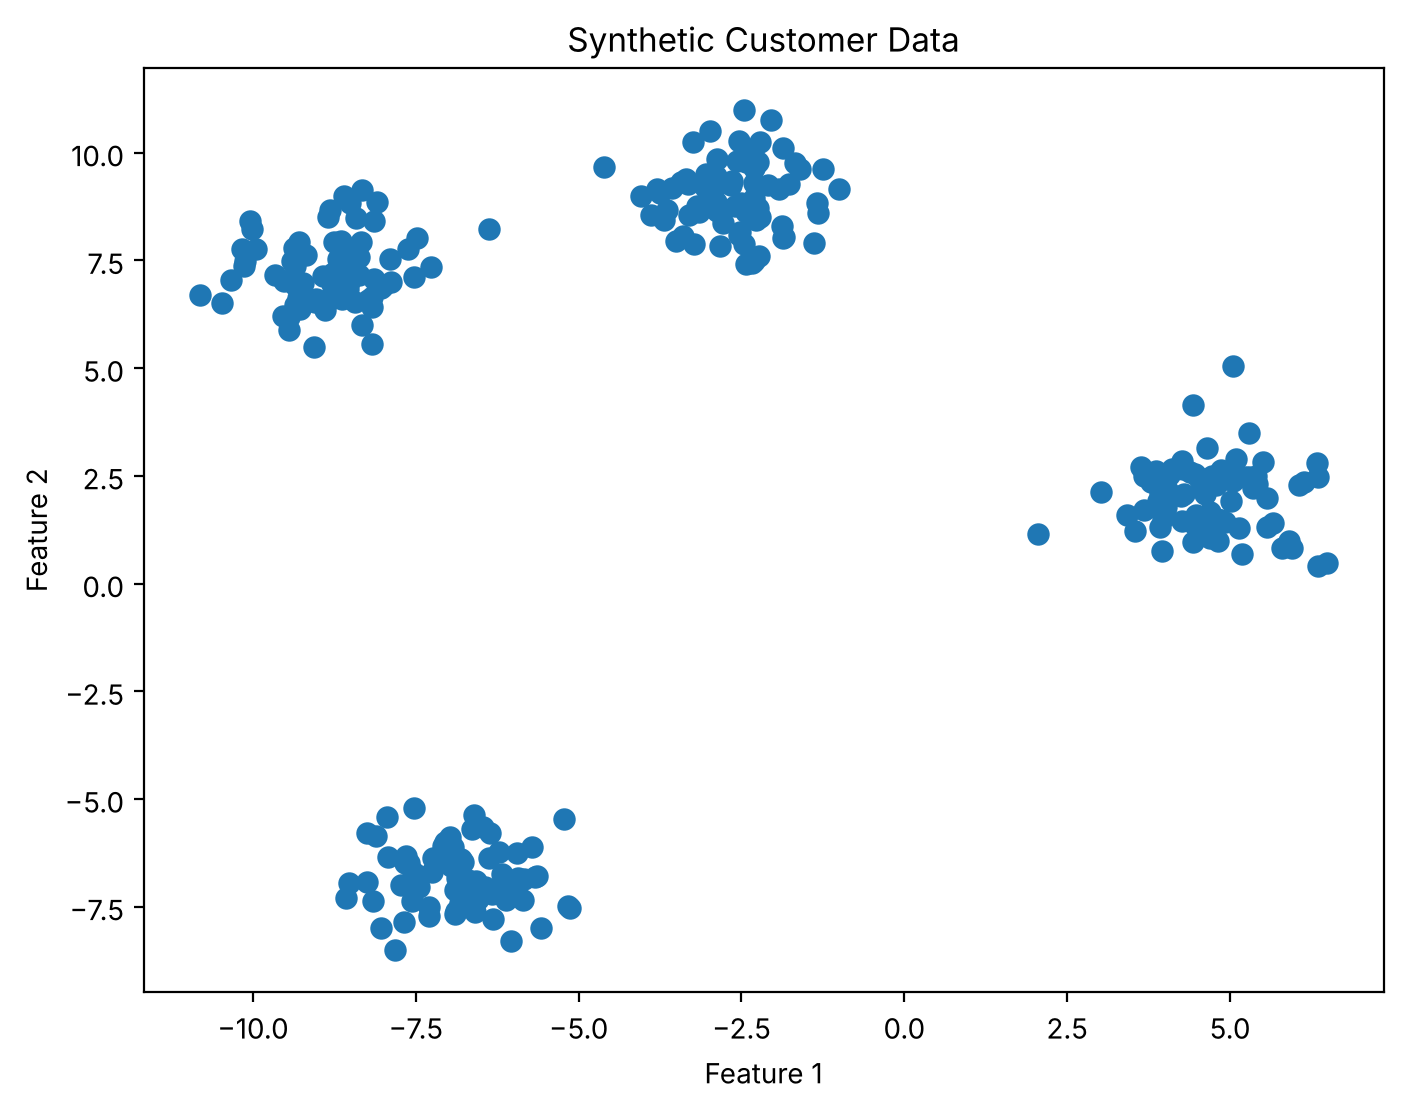

In [1]:
# Section 1 (Jamie Lopez): imports and synthetic data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs

# Generate synthetic data
X, y = make_blobs(n_samples=300, centers=4,
                  cluster_std=0.8, random_state=42)

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Synthetic Customer Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [2]:
# Section 1 (Jamie Lopez): quick look at the data before modeling
# y holds the true blob ids, but in an unsupervised setting we
# set it aside and only use X to find the groups.
customers = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])
print("Shape of X:", X.shape)
print()
print(customers.describe().round(2))

Shape of X: (300, 2)

       Feature 1  Feature 2
count     300.00     300.00
mean       -3.40       2.85
std         5.25       6.21
min       -10.82      -8.51
25%        -7.95      -0.99
50%        -4.87       5.27
75%        -0.24       8.04
max         6.49      10.98


**Section 1 interpretation (Jamie Lopez):** The dataset has 300 customers and 2 features. The scatter plot already shows separate groups of points, but the model is never given the labels in `y`. We only keep `y` so we can check later whether K-Means found the same groups on its own. This is the main difference from the supervised labs: there is no answer key during training.

### Task 1: Find the Optimal Number of Clusters (The Elbow Method)

**Completed by: Kerry Walker (Section 2)**

**Concept:** How do we know what `k` should be? The **Elbow Method** helps us decide. We run K-Means for a range of `k` values and for each `k`, we calculate the **inertia** (the sum of squared distances of samples to their closest cluster center). We then plot the inertia for each `k`. The "elbow" of the curve, the point where the inertia starts to decrease much more slowly, is a good estimate for the optimal `k`.

**Your Task:** Calculate and plot the inertia for `k` values from 1 to 10.

k =  1   inertia =   19780.25
k =  2   inertia =    9211.21
k =  3   inertia =    1919.36
k =  4   inertia =     362.47
k =  5   inertia =     329.27
k =  6   inertia =     294.61
k =  7   inertia =     261.56
k =  8   inertia =     232.01
k =  9   inertia =     209.10
k = 10   inertia =     188.72


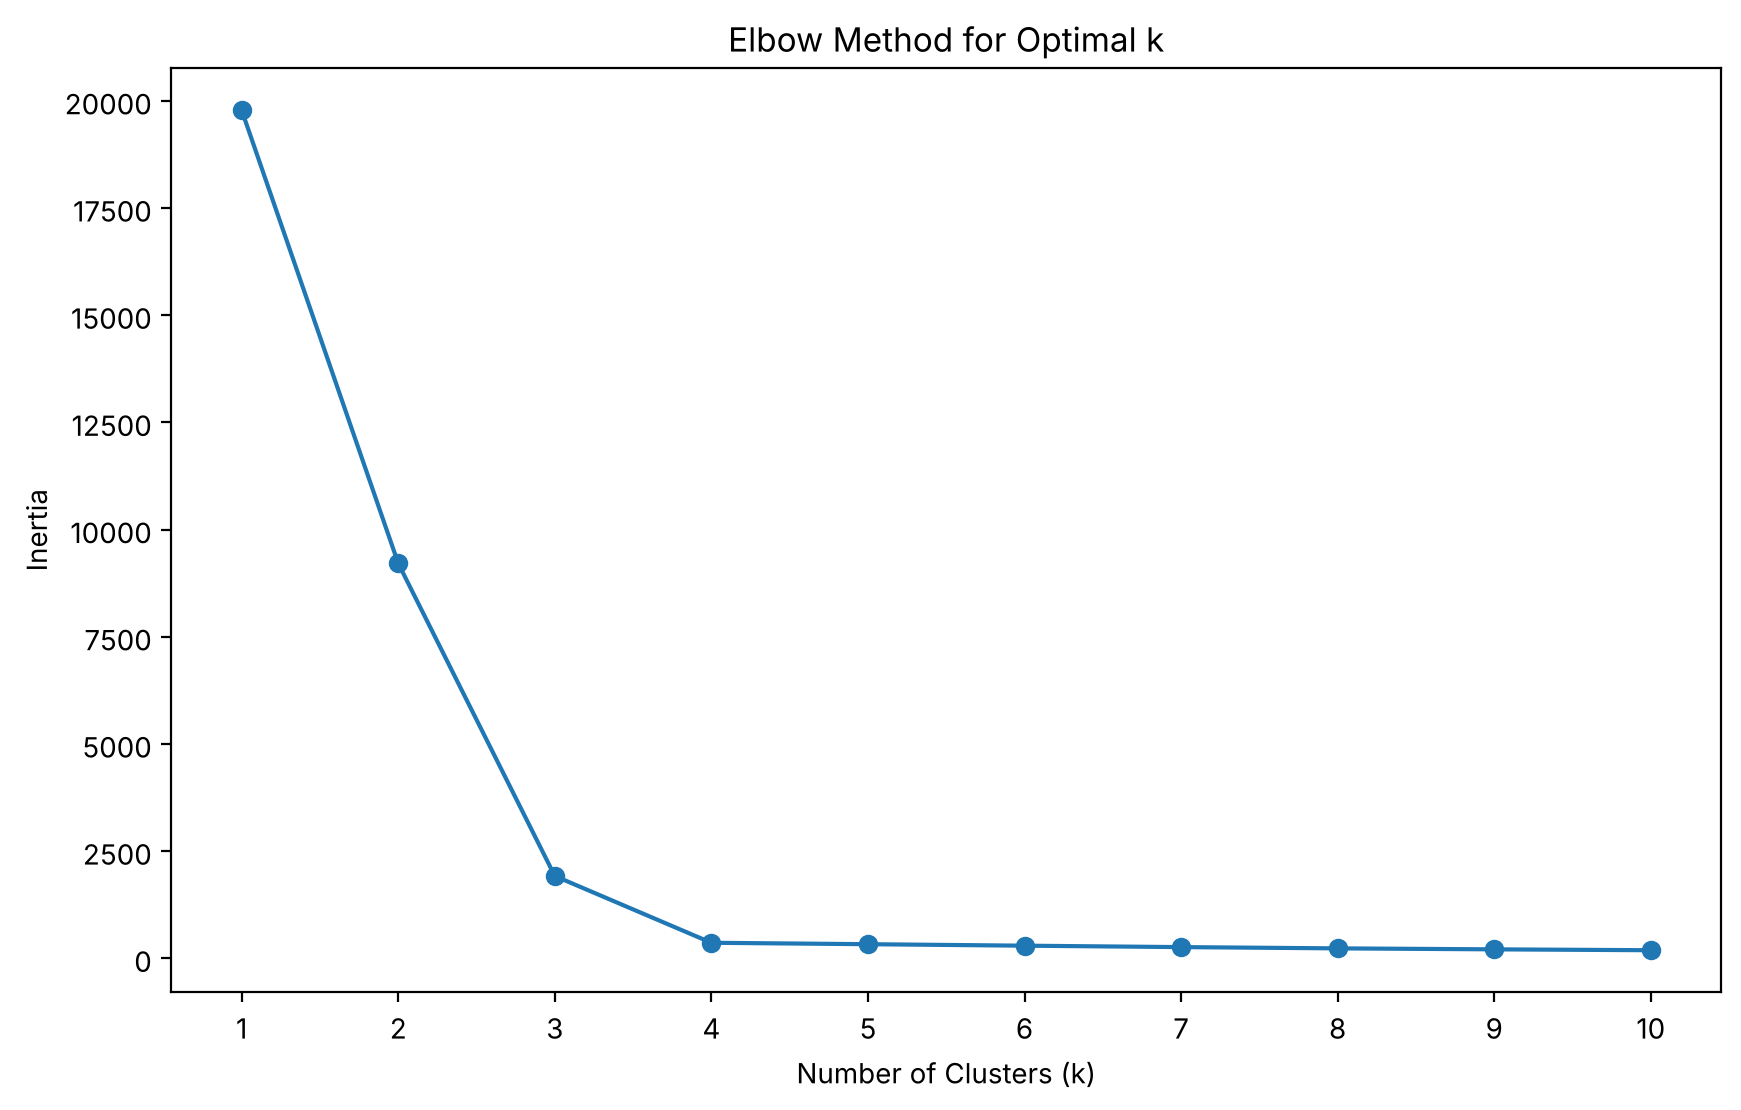

In [3]:
# Section 2 (Kerry Walker): Elbow Method
from sklearn.cluster import KMeans

# 1. Create an empty list to store the inertia values
inertia = []

# 2. Loop through k values from 1 to 10
for k in range(1, 11):
    # 3. Create and fit a KMeans model with n_clusters=k
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    # 4. Append the model's inertia_ to your list
    inertia.append(kmeans.inertia_)

# Print the values so the drop at each k is easy to read
for k, val in zip(range(1, 11), inertia):
    print(f"k = {k:2d}   inertia = {val:10.2f}")

# 5. Plot the results
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inertia, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.show()

In [4]:
# Section 2 (Kerry Walker): second opinion with silhouette score
# (slide 9). Higher is better; it needs at least 2 clusters.
from sklearn.metrics import silhouette_score

sil_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    sil_scores.append(silhouette_score(X, km.fit_predict(X)))

for k, s in zip(range(2, 11), sil_scores):
    print(f"k = {k:2d}   silhouette = {s:.3f}")
best_k = range(2, 11)[int(np.argmax(sil_scores))]
print("\nBest k by silhouette score:", best_k)

k =  2   silhouette = 0.603
k =  3   silhouette = 0.778
k =  4   silhouette = 0.834
k =  5   silhouette = 0.698
k =  6   silhouette = 0.588
k =  7   silhouette = 0.449
k =  8   silhouette = 0.332
k =  9   silhouette = 0.344
k = 10   silhouette = 0.359

Best k by silhouette score: 4


**Section 2 interpretation (Kerry Walker):** Inertia falls sharply from 19,780.25 at k = 1 to 1,919.36 at k = 3 and then to 362.47 at k = 4. After that, each extra cluster only removes about 20 to 35 units (329.27 at k = 5, 294.61 at k = 6), so the curve flattens and the elbow is clearly at k = 4. The silhouette scores agree: k = 4 has the highest score (0.834), and the score drops once we go past 4 because the extra clusters start splitting real groups in half. Two methods pointing to the same answer gives us more confidence in choosing k = 4.

### Task 2: Perform K-Means Clustering and Visualize

**Completed by: Angel Martinez (Section 3)**

From the elbow plot, it looks like `k=4` is the optimal number of clusters.

**Your Task:** Run K-Means with `n_clusters=4` and create a scatter plot showing the data points colored by their assigned cluster.

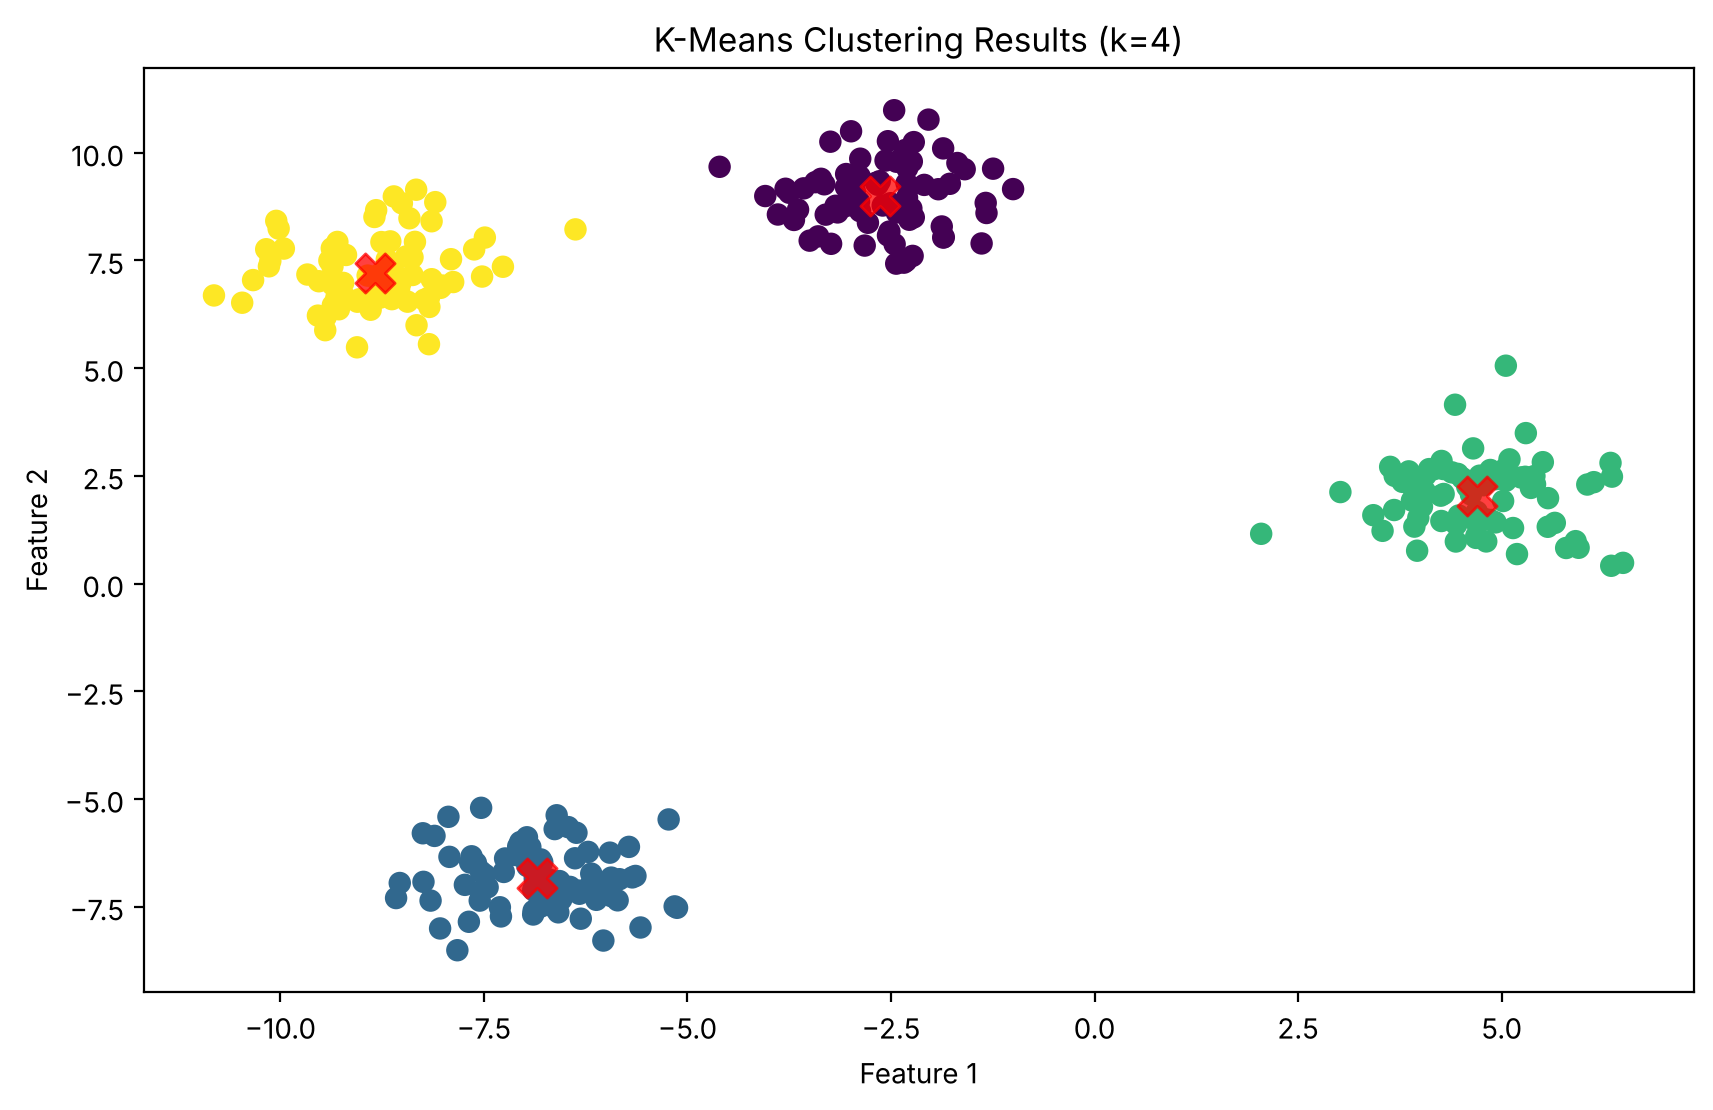

In [5]:
# Section 3 (Angel Martinez): K-Means with k = 4
# 1. Create and fit a KMeans model with n_clusters=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(X)

# 2. Get the cluster assignments for each data point
labels = kmeans.labels_

# 3. Get the coordinates of the cluster centers
centers = kmeans.cluster_centers_

# 4. Scatter plot of the data, colored by the labels
plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200,
            alpha=0.75, marker='X')  # Plot the centers
plt.title('K-Means Clustering Results (k=4)')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [6]:
# Section 3 (Angel Martinez): describe each cluster and check
# the result against the hidden blob ids we set aside earlier
from sklearn.metrics import adjusted_rand_score

summary = pd.DataFrame(centers, columns=["Center F1", "Center F2"])
summary["Customers"] = np.bincount(labels)
print(summary.round(2))
print(f"\nIterations to converge: {kmeans.n_iter_}")
print(f"Final inertia (k=4): {kmeans.inertia_:.2f}")

ari = adjusted_rand_score(y, labels)
print(f"Adjusted Rand Index vs. true groups: {ari:.3f}")
print()
print(pd.crosstab(pd.Series(y, name="True blob"),
                  pd.Series(labels, name="K-Means cluster")))

   Center F1  Center F2  Customers
0      -2.64       8.99         75
1      -6.84      -6.84         75
2       4.70       2.03         75
3      -8.83       7.22         75

Iterations to converge: 3
Final inertia (k=4): 362.47
Adjusted Rand Index vs. true groups: 1.000

K-Means cluster   0   1   2   3
True blob                      
0                75   0   0   0
1                 0   0  75   0
2                 0  75   0   0
3                 0   0   0  75


**Section 3 interpretation (Angel Martinez):** With k = 4, K-Means converged in only 3 iterations and placed exactly 75 customers in each cluster. The red X markers sit in the middle of each group, so each centroid is the "typical" customer for that segment. Because this is synthetic data we can peek at the hidden blob ids: the Adjusted Rand Index is 1.000 and the crosstab shows every true group mapped to exactly one cluster. The cluster numbers themselves do not match the blob numbers (for example blob 1 became cluster 2), which shows that cluster labels are just names; K-Means finds the groups but has no idea what they mean. In a real customer project we would still need to look at the centers and decide what each segment represents.

## Part 3: Principal Component Analysis (PCA)

**Completed by: Kristina Akpan (Section 4)**

**Concept:** PCA is a dimensionality reduction technique. It transforms the data into a new coordinate system of **principal components**. These components are orthogonal (uncorrelated) and are ordered by the amount of variance in the data they explain. By keeping only the first few principal components, we can reduce the number of dimensions in our data while losing as little information as possible.

**Use Cases:**

*   **Visualization:** Reducing high-dimensional data to 2 or 3 dimensions so we can plot it.
*   **Performance:** Speeding up model training by using fewer features.

**Problem:** We will use the Iris dataset, which has 4 features, and reduce it to 2 features so we can visualize it.

### Task 3: Apply PCA to the Iris Dataset

**Your Task:** Use `PCA` from `sklearn.decomposition` to reduce the 4-dimensional Iris dataset to 2 principal components and visualize the result.

Explained variance by component: [0.92461872 0.05306648]
Total variance explained by 2 components: 97.77%


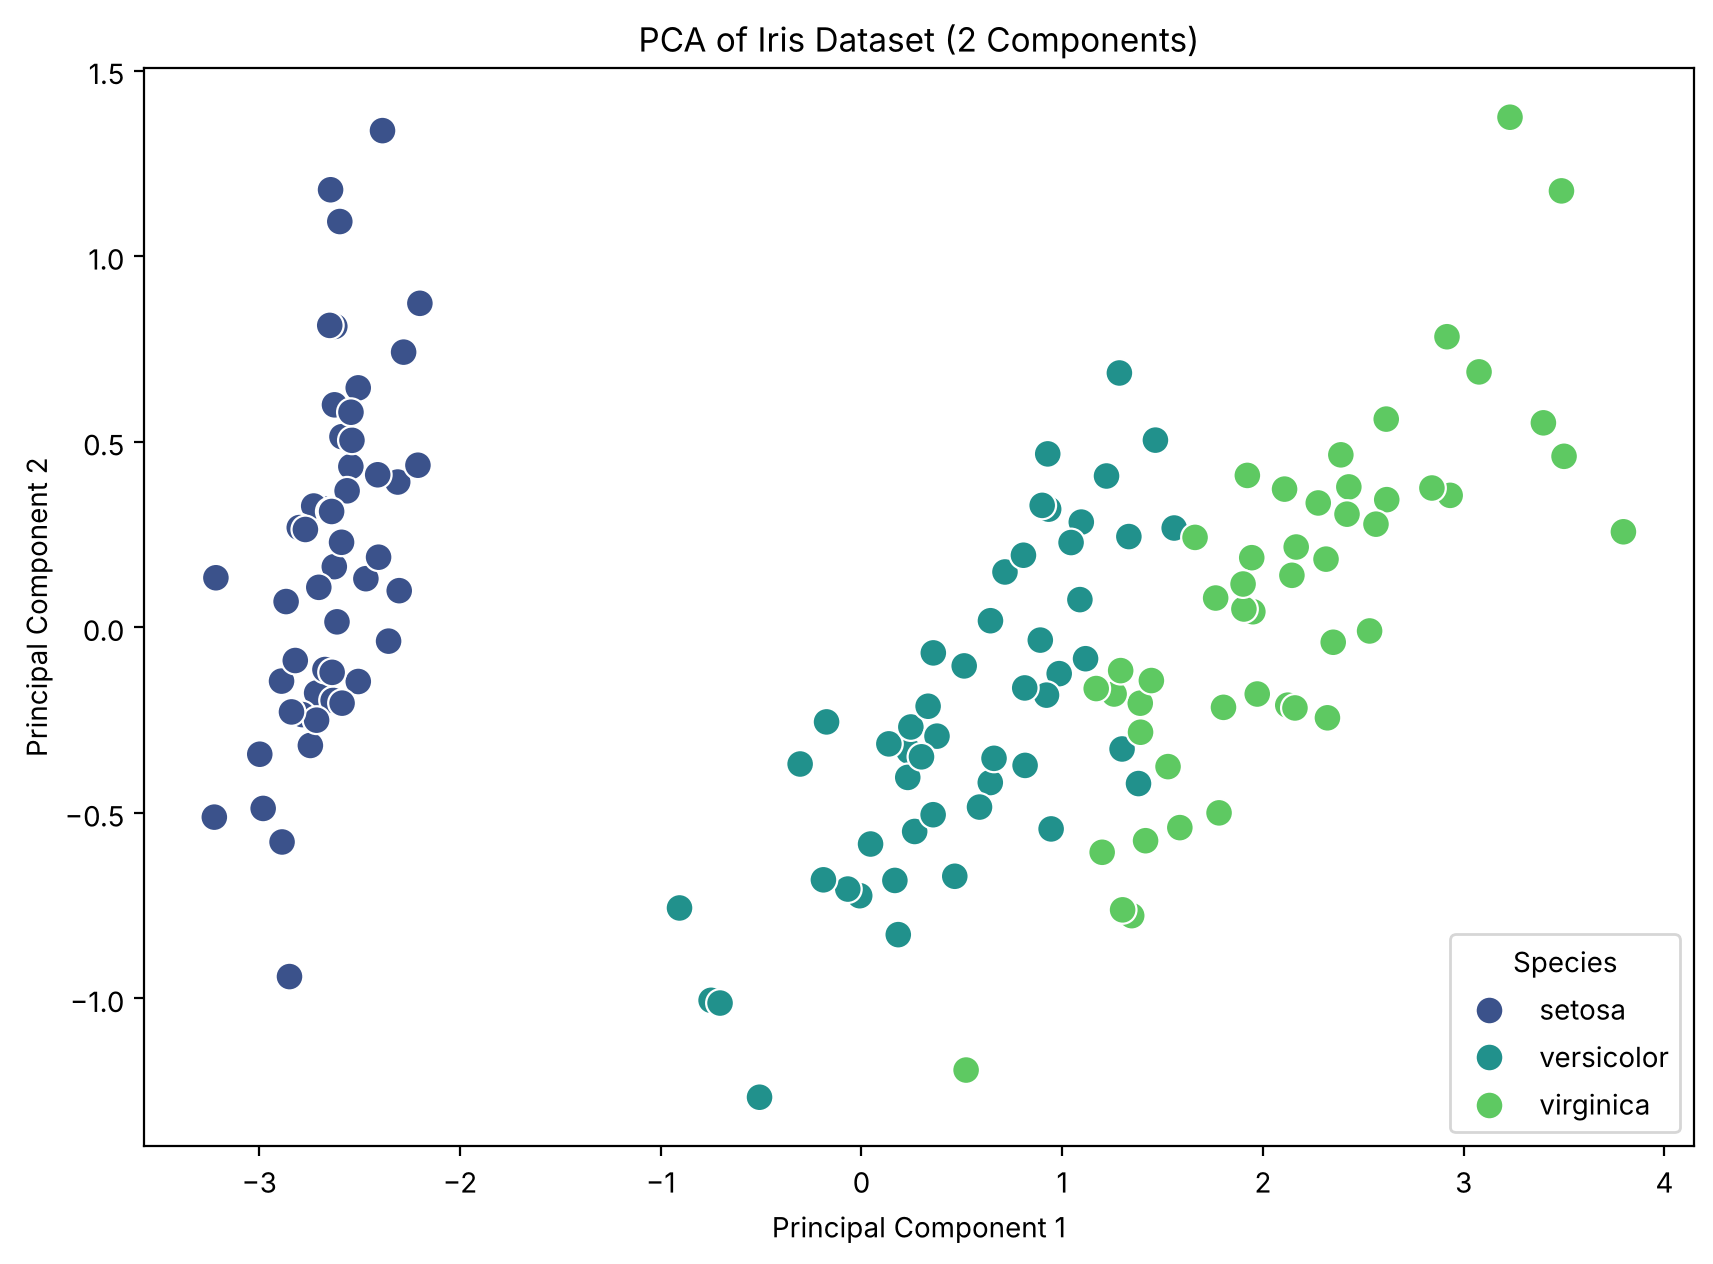

In [7]:
# Section 4 (Kristina Akpan): PCA on Iris
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris
import pandas as pd
import seaborn as sns  # used for the scatterplot below

# Load the data
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

# 1. Create a PCA instance to reduce to 2 components
pca = PCA(n_components=2)

# 2. Fit PCA to the data and transform it
X_pca = pca.fit_transform(X_iris)

# 3. Print the explained variance ratio
print("Explained variance by component: "
      f"{pca.explained_variance_ratio_}")
print("Total variance explained by 2 components: "
      f"{pca.explained_variance_ratio_.sum():.2%}")

# 4. Create a DataFrame with the PCA results for plotting
pca_df = pd.DataFrame(
    data=X_pca,
    columns=["Principal Component 1", "Principal Component 2"])
# Use species names instead of 0, 1, 2 so the legend is readable
pca_df["Species"] = iris.target_names[y_iris]

# 5. Plot the results
plt.figure(figsize=(10, 7))
sns.scatterplot(x="Principal Component 1",
                y="Principal Component 2", hue="Species",
                data=pca_df, palette='viridis', s=100)
plt.title('PCA of Iris Dataset (2 Components)')
plt.show()

In [8]:
# Section 4 (Kristina Akpan): what each component is made of
# and how much of the shape is kept as we add components
loadings = pd.DataFrame(pca.components_.T,
                        index=iris.feature_names,
                        columns=["PC1", "PC2"])
print("Loadings (weight of each original feature):")
print(loadings.round(3))

pca_all = PCA().fit(X_iris)
cum = np.cumsum(pca_all.explained_variance_ratio_)
print("\nCumulative variance with 1 to 4 components:")
for i, c in enumerate(cum, start=1):
    print(f"  {i} component(s): {c:.2%}")

Loadings (weight of each original feature):
                     PC1    PC2
sepal length (cm)  0.361  0.657
sepal width (cm)  -0.085  0.730
petal length (cm)  0.857 -0.173
petal width (cm)   0.358 -0.075

Cumulative variance with 1 to 4 components:
  1 component(s): 92.46%
  2 component(s): 97.77%
  3 component(s): 99.48%
  4 component(s): 100.00%


In [9]:
# Section 4 (Kristina Akpan): slide 24 says PCA is sensitive to
# scaling, so compare against standardized features
from sklearn.preprocessing import StandardScaler

X_iris_std = StandardScaler().fit_transform(X_iris)
pca_std = PCA(n_components=2).fit(X_iris_std)
print("Standardized explained variance: "
      f"{pca_std.explained_variance_ratio_.round(4)}")
print("Standardized total (2 components): "
      f"{pca_std.explained_variance_ratio_.sum():.2%}")

Standardized explained variance: [0.7296 0.2285]
Standardized total (2 components): 95.81%


**Section 4 interpretation (Kristina Akpan):** Two principal components keep 97.77% of the variance in the 4 original Iris features (PC1 alone keeps 92.46% and PC2 adds 5.31%). In the plot, setosa forms its own group on the left side of PC1, while versicolor and virginica sit next to each other with a small overlap. The loadings show that PC1 is driven mostly by petal length (0.857), so the main direction of variation in Iris is basically flower size, especially petal size. PC2 is mostly sepal width and sepal length. When the features are standardized first, the two components still keep 95.81%, but the split changes to 72.96% and 22.85%. That happens because petal length has the largest raw range and dominates unscaled PCA, which matches the scaling warning on slide 24.

### Extension: Combining PCA and K-Means

**Completed by: Thomas Jaymon (Section 5)**

**Concept:** Slide 25 describes a combined workflow: apply PCA first to reduce dimensions, then run K-Means on the principal components. Here we cluster the 2 component Iris data from Section 4 without using the species labels, then compare the clusters to the real species afterward.

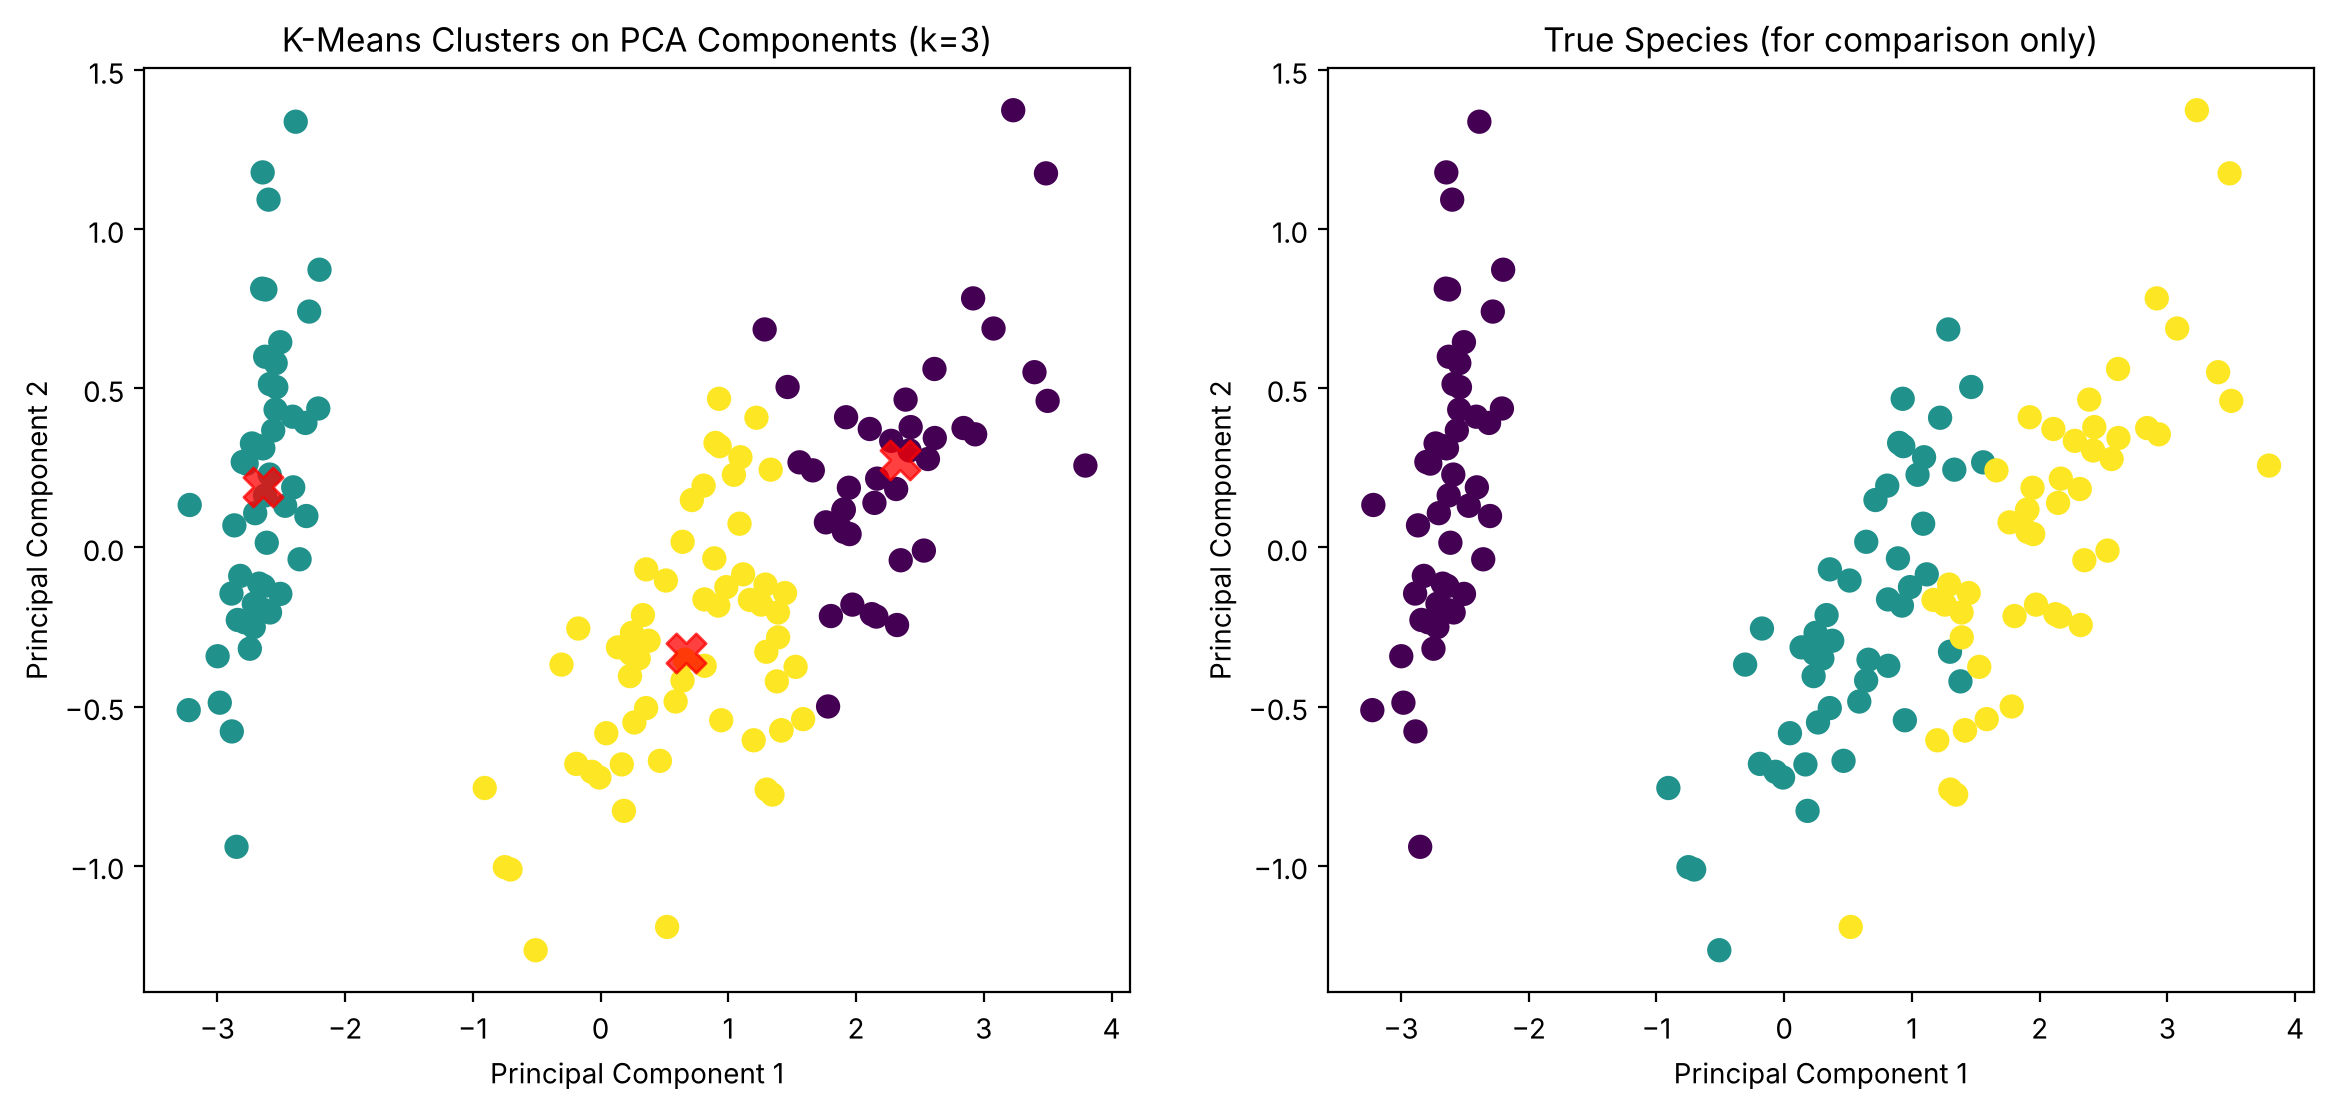

In [10]:
# Section 5 (Thomas Jaymon): K-Means on the PCA components
from sklearn.metrics import adjusted_rand_score

# Iris has 3 species, so we use k = 3 (domain knowledge, slide 8)
km_iris = KMeans(n_clusters=3, random_state=42, n_init=10)
iris_clusters = km_iris.fit_predict(X_pca)
iris_centers = km_iris.cluster_centers_

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=iris_clusters,
                cmap='viridis', s=60)
axes[0].scatter(iris_centers[:, 0], iris_centers[:, 1],
                c='red', s=200, alpha=0.75, marker='X')
axes[0].set_title('K-Means Clusters on PCA Components (k=3)')
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_iris,
                cmap='viridis', s=60)
axes[1].set_title('True Species (for comparison only)')
for ax in axes:
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
plt.show()

In [11]:
# Section 5 (Thomas Jaymon): how well do the clusters match
# the real species? Also compare with clustering on all 4
# original features to see what PCA cost or saved.
ari_pca = adjusted_rand_score(y_iris, iris_clusters)
km_full = KMeans(n_clusters=3, random_state=42, n_init=10)
ari_full = adjusted_rand_score(y_iris, km_full.fit_predict(X_iris))

print(f"ARI, K-Means on 2 PCA components: {ari_pca:.3f}")
print(f"ARI, K-Means on 4 original features: {ari_full:.3f}")
print()
print(pd.crosstab(
    pd.Series(iris.target_names[y_iris], name="Species"),
    pd.Series(iris_clusters, name="Cluster")))

ARI, K-Means on 2 PCA components: 0.716
ARI, K-Means on 4 original features: 0.730

Cluster      0   1   2
Species               
setosa       0  50   0
versicolor   3   0  47
virginica   36   0  14


**Section 5 extension interpretation (Thomas Jaymon):** K-Means on the 2 PCA components put all 50 setosa flowers into their own cluster with no mistakes. Versicolor and virginica were harder: 47 of 50 versicolor landed together, but 14 virginica were grouped with them, so 133 of 150 flowers (about 88.7%) ended up with their own species. This matches the PCA plot from Section 4, where those two species overlap. The Adjusted Rand Index was 0.716 on the 2 components versus 0.730 on all 4 original features, so cutting the data in half barely changed the result. That is the practical benefit from slide 25: almost the same clustering quality with half the features. It also shows that K-Means can only separate groups that are actually separated in the data; no choice of k fixes real overlap.

## 📝 Knowledge Check

**Completed by: Thomas Jaymon (Section 5)**

**Instructions:** Answer the following questions in this markdown cell.

1.  **What is the fundamental difference between supervised and unsupervised learning?**
2.  **In the K-Means elbow plot, why don't we just choose the largest possible `k` to get the lowest inertia?**
3.  **In the PCA results, the first two principal components explained over 95% of the variance. What does this tell you about the original 4-dimensional Iris dataset?**

**Answers (Thomas Jaymon):**

1.  **Supervised vs. unsupervised:** Supervised learning trains on labeled data, so every example has features (X) and a known answer (y), and the model learns to map X to y. It can be scored directly against those answers. Unsupervised learning only gets X. There is no answer key, so the goal is to discover structure such as groups (clustering) or the main directions of variation (dimensionality reduction). In this lab, K-Means never saw `y`; we only used it afterward to check the result.

2.  **Why not the largest k:** Inertia always goes down as k goes up, and it reaches 0 when every point is its own cluster. That would be a perfect score that tells us nothing, because the model would just memorize individual points instead of finding real groups. In our elbow plot, going from 3 to 4 clusters cut inertia from 1,919.36 to 362.47, but going from 4 to 10 only cut it to 188.72. Those extra clusters split real groups apart, which is also why the silhouette score fell after k = 4. We want the point of diminishing returns, not the minimum.

3.  **What 95%+ variance means for Iris:** Our first two components explained 97.77% of the variance, so the 4 measurements are highly correlated and carry a lot of overlapping information. The data mostly lies close to a flat 2D surface inside the 4D space. In practice, petal length, petal width and sepal length all rise together as flowers get bigger, so one "size" direction (PC1, 92.46%) captures most of the differences. This means we can plot Iris in 2D, or train a model on 2 features instead of 4, while losing only about 2% of the information. Our extension backs this up: K-Means on just the 2 components scored an Adjusted Rand Index of 0.716, nearly the same as 0.730 on all 4 features.